









































































Importing Libraries$

In [1]:
import sys
sys.path.insert(0, r"D:\PythonPackages\Python311\site-packages")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

print("All libraries imported successfully!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All done")

All libraries imported successfully!
Pandas: 3.1.0
NumPy: 2.4.6
SciPy: 1.17.1
Scikit-learn: 1.9.1
All done


Data Cleaning & Preprocessing


In [2]:
df = pd.read_csv("data/GlobalWeatherRepository.csv")
df.columns = df.columns.str.lower().str.replace(" ","_")
df["last_updated"] = pd.to_datetime(df["last_updated"], errors='coerce')
df = df.drop_duplicates()
numerics_cols = df.select_dtypes(include=np.number).columns

for col in numerics_cols:
    df[col] = df[col].fillna(df[col].median())

categorical_cols = df.select_dtypes(include=np.number).columns

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])


for col in numerics_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 -  q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 *iqr 
    df[col] = df[col].clip(lower, upper)

df = df.sort_values("last_updated")
df.head()

,country,location_name,latitude,longitude,timezone,last_updated_epoch,last_updated,temperature_celsius,temperature_fahrenheit,condition_text,...,air_quality_pm2.5,air_quality_pm10,air_quality_us-epa-index,air_quality_gb-defra-index,sunrise,sunset,moonrise,moonset,moon_phase,moon_illumination
186,United States of America,Washington Park,46.60,-91.91355,America/Los_Angeles,1715849100,2024-05-16 01:45:00,16.1,61.0,Clear,...,6.30,7.1000,1.0,1,05:26 AM,08:31 PM,01:36 PM,02:52 AM,Waxing Gibbous,55
40,Costa Rica,San Juan,9.97,-84.08000,America/Costa_Rica,1715849100,2024-05-16 02:45:00,21.0,69.8,Fog,...,21.70,23.3000,2.0,2,05:15 AM,05:51 PM,12:42 PM,12:37 AM,Waxing Gibbous,55
110,Mexico,Mexico City,19.43,-91.91355,America/Mexico_City,1715849100,2024-05-16 02:45:00,20.8,69.4,Clear,...,35.10,48.0000,2.0,3,06:01 AM,07:05 PM,01:37 PM,01:49 AM,Waxing Gibbous,55
52,El Salvador,San Salvador,13.71,-89.20000,America/El_Salvador,1715849100,2024-05-16 02:45:00,26.0,78.8,Moderate or heavy rain with thunder,...,20.40,28.1000,2.0,2,05:30 AM,06:16 PM,01:00 PM,01:02 AM,Waxing Gibbous,55
68,Guatemala,Guatemala City,14.62,-90.53000,America/Guatemala,1715849100,2024-05-16 02:45:00,20.0,68.0,Mist,...,53.95,81.4875,3.5,6,05:34 AM,06:23 PM,01:05 PM,01:09 AM,Waxing Gibbous,55


Explotray Data Analysis (EDA)

<class 'pandas.DataFrame'>
Index: 170928 entries, 186 to 170909
Data columns (total 41 columns):
 #   Column                        Non-Null Count   Dtype         
---  ------                        --------------   -----         
 0   country                       170928 non-null  str           
 1   location_name                 170928 non-null  str           
 2   latitude                      170928 non-null  float64       
 3   longitude                     170928 non-null  float64       
 4   timezone                      170928 non-null  str           
 5   last_updated_epoch            170928 non-null  int64         
 6   last_updated                  170928 non-null  datetime64[us]
 7   temperature_celsius           170928 non-null  float64       
 8   temperature_fahrenheit        170928 non-null  float64       
 9   condition_text                170928 non-null  str           
 10  wind_mph                      170928 non-null  float64       
 11  wind_kph                   

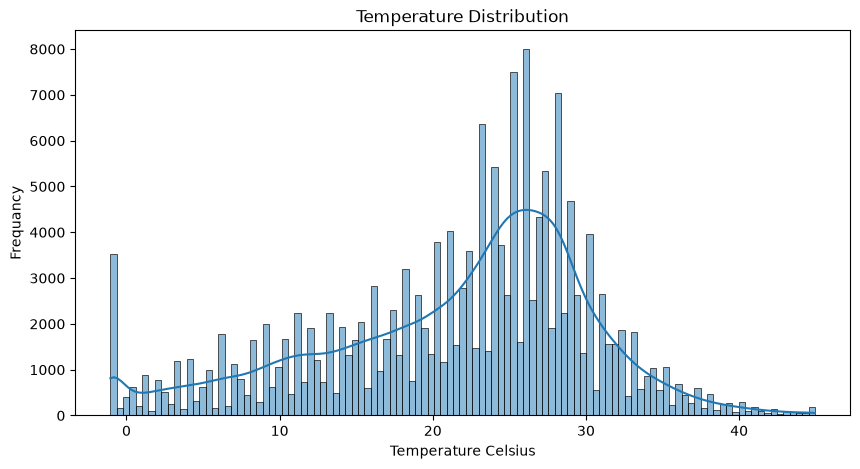

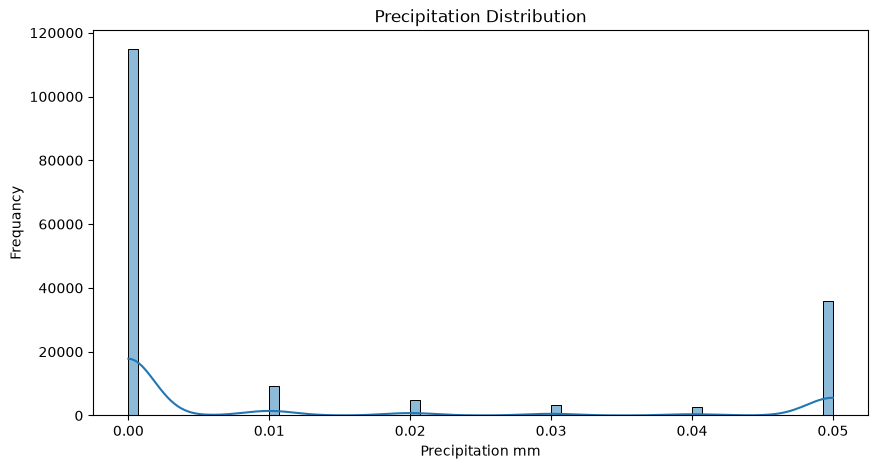

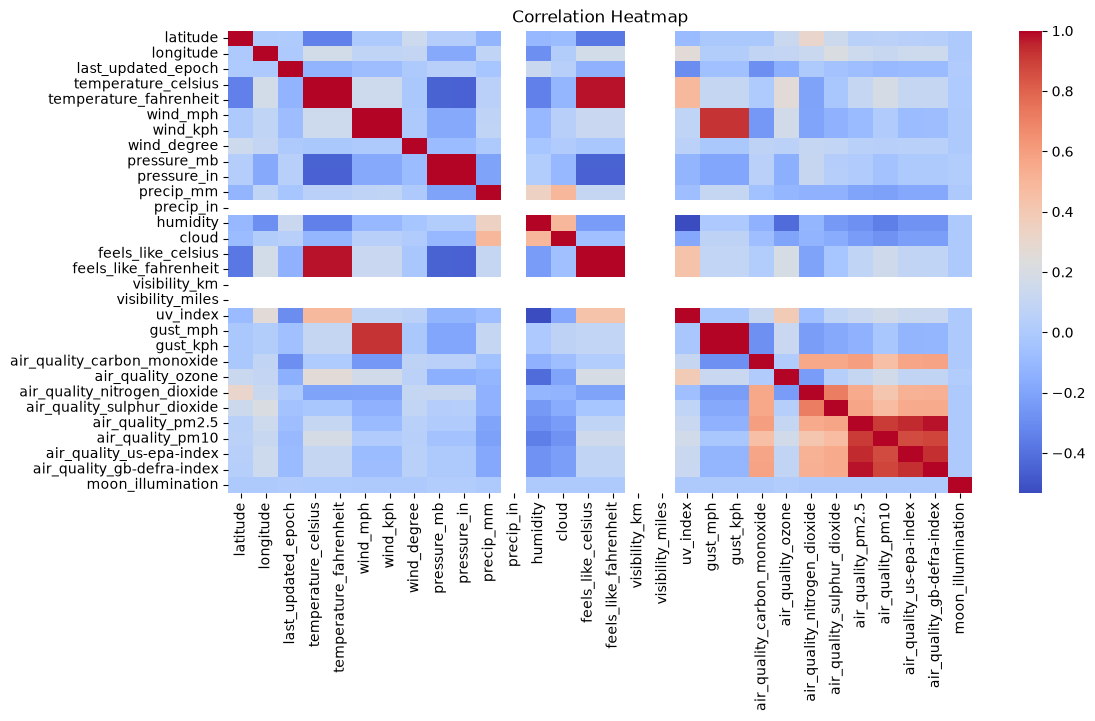

In [3]:
print(df.info())
print(df.describe())

plt.figure(figsize=(10, 5))
sns.histplot(df["temperature_celsius"], kde=True)
plt.title("Temperature Distribution")
plt.xlabel("Temperature Celsius")
plt.ylabel("Frequancy")
plt.show()


plt.figure(figsize=(10, 5))
sns.histplot(df["precip_mm"], kde=True)
plt.title("Precipitation Distribution")
plt.xlabel("Precipitation mm")
plt.ylabel("Frequancy")
plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(df[numerics_cols].corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


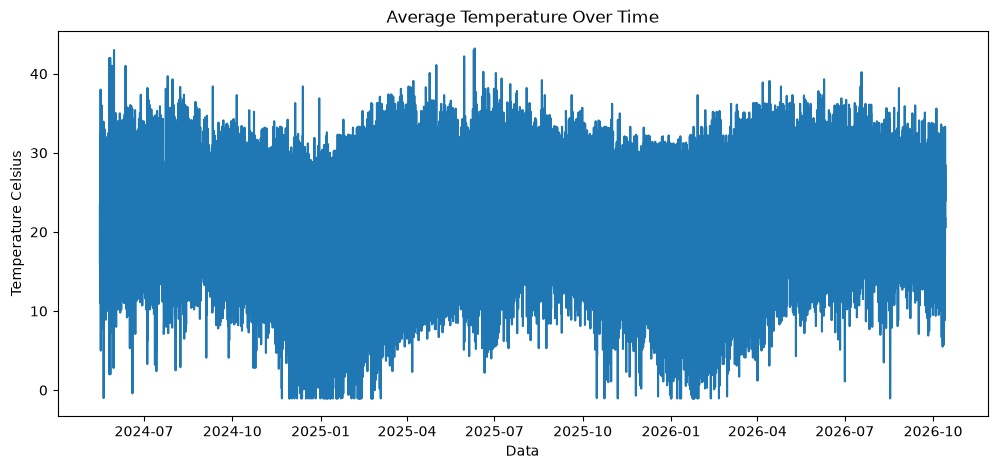

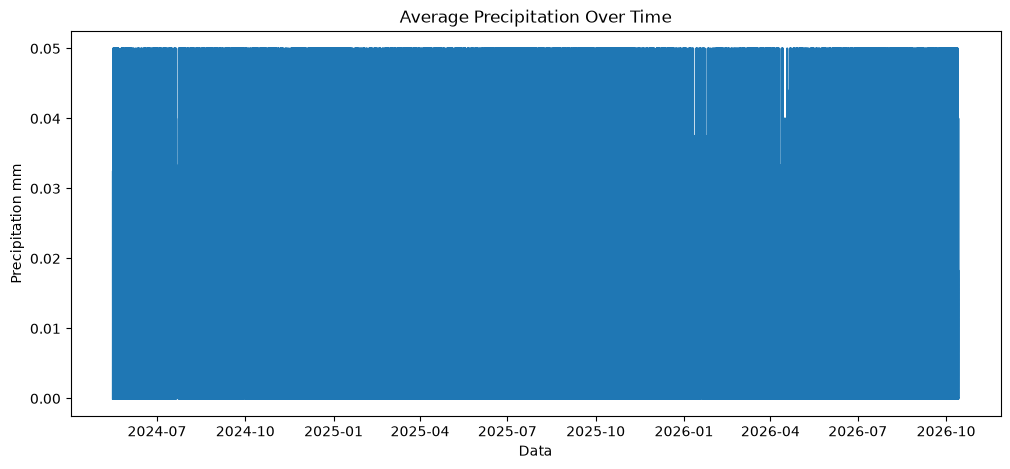

In [4]:
daily_weather = df.groupby("last_updated").agg({"temperature_celsius": "mean", "precip_mm": "mean"}).reset_index()
plt.figure(figsize=(12, 5))
plt.plot(daily_weather["last_updated"], daily_weather["temperature_celsius"])
plt.title("Average Temperature Over Time")
plt.xlabel("Data")
plt.ylabel("Temperature Celsius")
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(daily_weather["last_updated"], daily_weather["precip_mm"])
plt.title("Average Precipitation Over Time")
plt.xlabel("Data")
plt.ylabel("Precipitation mm")
plt.show()


Model Building

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

model_data = df.copy()


model_data["year"] = model_data["last_updated"].dt.year
model_data["month"] = model_data["last_updated"].dt.month
model_data["day"] = model_data["last_updated"].dt.day
model_data["dayofyear"] = model_data["last_updated"].dt.dayofyear


features = ["humidity", "pressure_mb", "wind_kph", "precip_mm", "cloud", "uv_index",
            "year", "month", "day", "dayofyear"]

target = "temperature_celsius"

model_data = model_data.dropna(subset=features + [target])

X = model_data[features]
Y = model_data[target]

split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
Y_train = Y.iloc[:split_index]
Y_test = Y.iloc[split_index:]

rf_model = RandomForestRegressor(
    n_estimators=20,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=1
)

rf_model.fit(X_train, Y_train)

predictions = rf_model.predict(X_test)

mae = mean_absolute_error(Y_test, predictions)
rmse = np.sqrt(mean_squared_error(Y_test, predictions))
r2 = r2_score(Y_test, predictions)

print("Random Forest Results")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

C:\Users\Noor Fatima\AppData\Local\Temp\ipykernel_9772\1181806378.py:11: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  model_data["dayofyear"] = model_data["last_updated"].dt.dayofyear


Random Forest Results
MAE: 4.355759217818795
RMSE: 5.591708827967916
R2 Score: 0.41754164248850445


Advanced Assessment

Advanced EDA

Number of anomalies: 8547


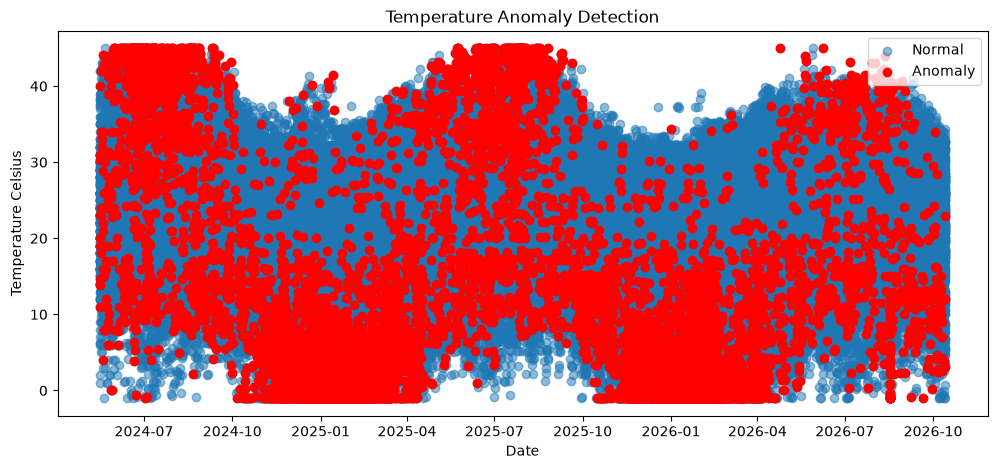

In [6]:
from sklearn.ensemble import IsolationForest

anomaly_features = ["temperature_celsius", "humidity", "pressure_mb", "wind_kph", "precip_mm"]

anomaly_df = df.dropna(subset=anomaly_features)

iso_model = IsolationForest(contamination=0.05, random_state=42)

anomaly_df["anomaly"] = iso_model.fit_predict(anomaly_df[anomaly_features])

anomalies = anomaly_df[anomaly_df["anomaly"] == -1]

print("Number of anomalies:", len(anomalies))

plt.figure(figsize=(12, 5))
plt.scatter(anomaly_df["last_updated"],anomaly_df["temperature_celsius"],
            label="Normal",alpha=0.5)

plt.scatter(anomalies["last_updated"],anomalies["temperature_celsius"],
            label="Anomaly",color="red")

plt.title("Temperature Anomaly Detection")
plt.xlabel("Date")
plt.ylabel("Temperature Celsius")
plt.legend()
plt.show()

Forecasting With Multiple Models

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=20,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=1
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, Y_train)
    preds = model.predict(X_test)

    results.append({"Model": name, "MAE": mean_absolute_error(Y_test, preds),
                    "RMSE": np.sqrt(mean_squared_error(Y_test, preds)),
                    "R2 Score": r2_score(Y_test, preds)})


results_df = pd.DataFrame(results)
print(results_df)

               Model       MAE      RMSE  R2 Score
0  Linear Regression  5.681235  6.716391  0.159674
1      Random Forest  4.355759  5.591709  0.417542
2  Gradient Boosting  4.233131  5.291820  0.478342


Ensamble Model

In [8]:
linear_model = LinearRegression()
rf_model = RandomForestRegressor(
    n_estimators=20,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=1
)
gb_model = GradientBoostingRegressor(random_state=42)

linear_model.fit(X_train, Y_train)
rf_model.fit(X_train, Y_train)
gb_model.fit(X_train, Y_train)

pred_linear = linear_model.predict(X_test)
pred_rf = rf_model.predict(X_test)
pred_gb = gb_model.predict(X_test)

ensamble_predictions = (pred_linear + pred_rf + pred_gb) / 3

ensamble_mae = mean_absolute_error(Y_test, ensamble_predictions)
ensamble_rmse = np.sqrt(mean_squared_error(Y_test, ensamble_predictions))
ensamble_r2 = r2_score(Y_test, ensamble_predictions)

print("Ensamble Model Results")
print("MAE:", ensamble_mae)
print("RMSE:", ensamble_rmse)
print("R2 Score:", ensamble_r2)


Ensamble Model Results
MAE: 4.564257508429073
RMSE: 5.504017382017911
R2 Score: 0.4356670903733443


Unique Analysis

Climate Analysis

                  country  temperature_celsius   humidity  precip_mm
158         Saudi Arabien            44.950000   7.000000   0.000000
114              Marrocos            40.300000  14.000000   0.000000
189          Turkménistan            37.800000  11.000000   0.000000
208                Турция            34.000000  44.000000   0.000000
147                 Qatar            32.964669  40.231735   0.000400
194  United Arab Emirates            32.524943  45.169704   0.000319
29               Cambodia            32.093273  59.003421   0.017001
136                  Oman            31.800797  53.246014   0.000456
94                 Kuwait            31.542645  27.559863   0.001494
48               Djibouti            31.488057  56.072000   0.005806


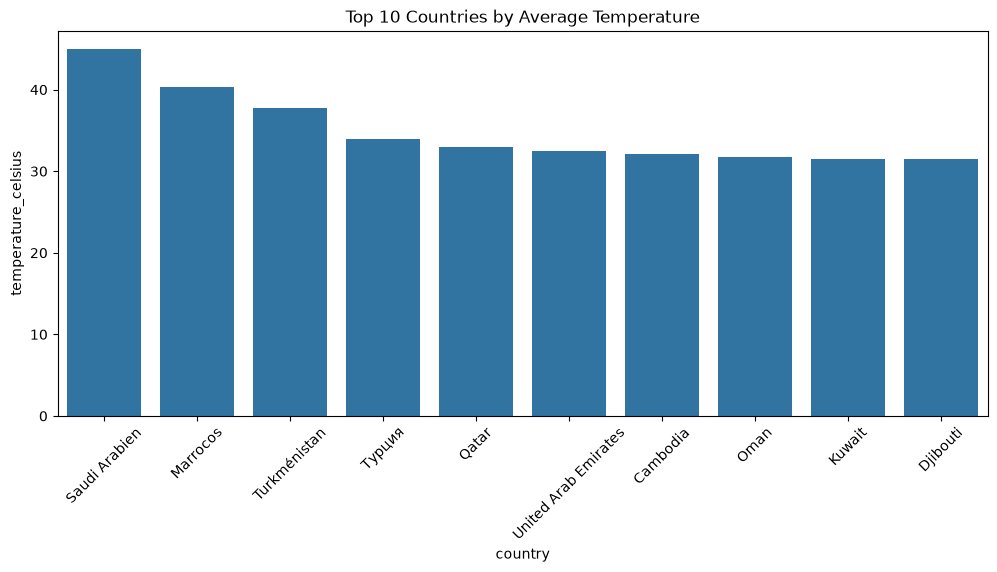

In [9]:
country_climate = df.groupby("country").agg({"temperature_celsius": "mean",
                                             "humidity": "mean", 
                                             "precip_mm": "mean"}).reset_index()

top_hot_countries =  country_climate.sort_values("temperature_celsius",ascending=False).head(10)

print(top_hot_countries)
plt.figure(figsize=(12, 5))
sns.barplot(data=top_hot_countries,x="country",y="temperature_celsius")
plt.xticks(rotation=45)
plt.title("Top 10 Countries by Average Temperature")
plt.show()

Environmental Impact

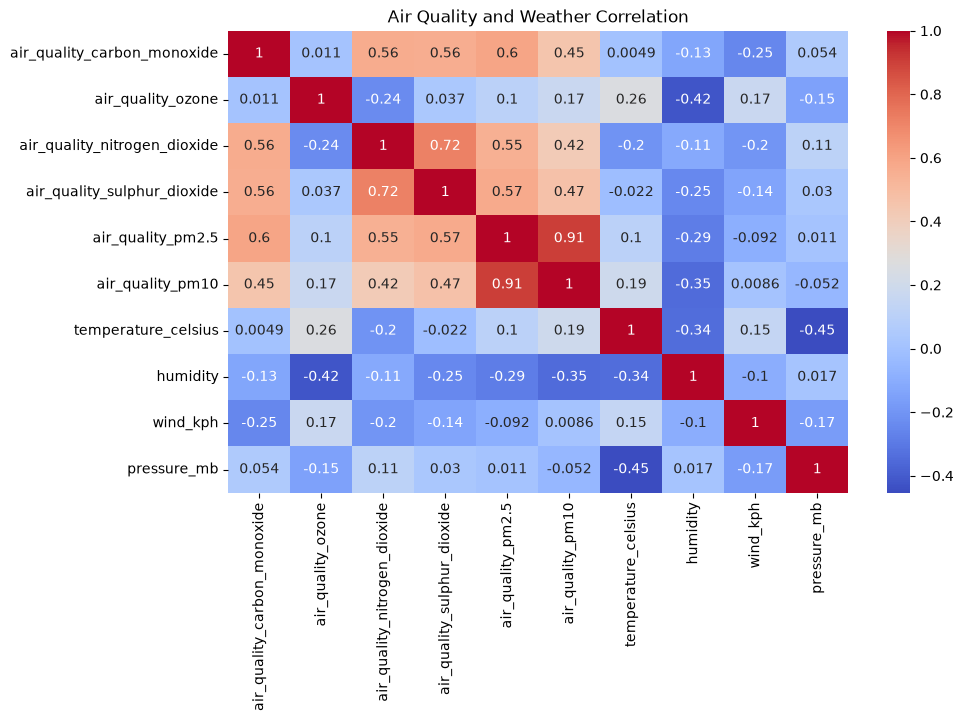

In [10]:
air_quatlity_cols = ["air_quality_carbon_monoxide","air_quality_ozone",
                     "air_quality_nitrogen_dioxide","air_quality_sulphur_dioxide",
                     "air_quality_pm2.5","air_quality_pm10"]

available_air_cols = [col for col in air_quatlity_cols if col in df.columns]
env_cols = available_air_cols + ["temperature_celsius", "humidity", "wind_kph", "pressure_mb"]
env_corr = df[env_cols].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(env_corr, annot=True, cmap="coolwarm")
plt.title("Air Quality and Weather Correlation")
plt.show()

Feature Importance

       Feature  Importance
5     uv_index    0.410228
1  pressure_mb    0.315533
0     humidity    0.132750
9    dayofyear    0.064327
4        cloud    0.029616
2     wind_kph    0.019362
6         year    0.016794
3    precip_mm    0.005822
8          day    0.004388
7        month    0.001181


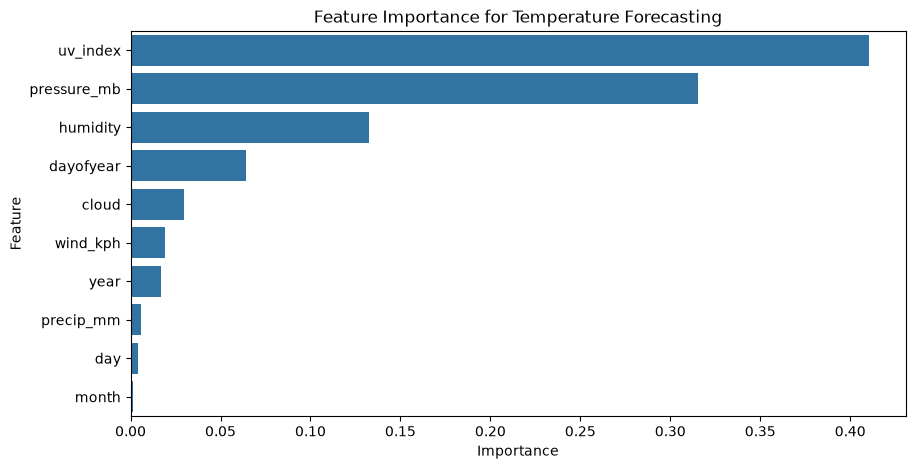

In [11]:
importance_df = pd.DataFrame({"Feature": features, "Importance": rf_model.feature_importances_
                              }).sort_values("Importance", ascending=False)

print(importance_df)
plt.figure(figsize=(10, 5))
sns.barplot(data=importance_df,x="Importance",y="Feature")
plt.title("Feature Importance for Temperature Forecasting")
plt.show()

Spatial Analysis

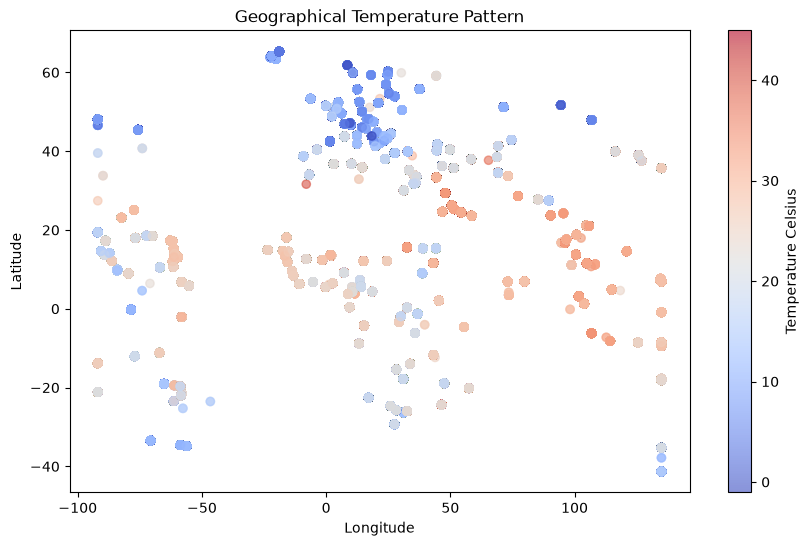

In [12]:
plt.figure(figsize=(10, 6))
plt.scatter(df["longitude"],df["latitude"],c=df["temperature_celsius"],
            cmap="coolwarm",alpha=0.6)

plt.colorbar(label="Temperature Celsius")
plt.title("Geographical Temperature Pattern")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

Geographical Patterns

In [13]:
geo_summary = df.groupby(["country", "location_name"]).agg({"temperature_celsius": "mean",
                                                           "humidity": "mean",
                                                           "precip_mm": "mean",
                                                           "wind_kph": "mean"
                                                           }).reset_index()

print(geo_summary.head(20))

                country      location_name  temperature_celsius   humidity  \
0           Afghanistan              Kabul            20.023349  26.203872   
1               Albania             Tirana            19.660091  56.993158   
2               Algeria            Algiers            20.783904  66.001142   
3               Andorra   Andorra La Vella             9.522665  65.763098   
4                Angola             Luanda            25.218337  77.292711   
5   Antigua and Barbuda       Saint John's            26.454005  78.542334   
6             Argentina       Buenos Aires            14.154909  82.392694   
7               Armenia            Yerevan            17.748861  44.857631   
8             Australia           Canberra            15.172235  62.827822   
9             Australia          Melbourne            11.900000  74.000000   
10              Austria             Vienna            13.556385  67.503991   
11           Azerbaijan               Baku            19.723489 

Pakistand Data

In [14]:
pakistan_data = df[
    df["country"].str.contains("Pakistan", case=False, na=False)
]

print("Pakistan records:", len(pakistan_data))
print("Available locations:")
print(pakistan_data["location_name"].unique())

Pakistan records: 876
Available locations:
<StringArray>
['Islamabad']
Length: 1, dtype: str


Islamabad Data

In [15]:
islamabad_df = pakistan_data.copy()

islamabad_df = islamabad_df.sort_values("last_updated")

print("Total records:", len(islamabad_df))
print("First date:", islamabad_df["last_updated"].min())
print("Last date:", islamabad_df["last_updated"].max())
print("Unique dates:", islamabad_df["last_updated"].nunique())

Total records: 876
First date: 2024-05-16 13:45:00
Last date: 2026-10-13 10:30:00
Unique dates: 876


In [16]:
print(islamabad_df["last_updated"].diff().value_counts().head(10))

last_updated
1 days 00:00:00    364
0 days 23:45:00    205
1 days 00:15:00    185
0 days 23:30:00     53
1 days 00:30:00     37
0 days 22:45:00      6
1 days 00:45:00      4
0 days 23:15:00      4
1 days 01:15:00      4
0 days 23:00:00      2
Name: count, dtype: int64


Daily Temperature Data

In [17]:
daily_weather = (
    islamabad_df
    .set_index("last_updated")
    .resample("D")["temperature_celsius"]
    .mean()
    .dropna()
)

print("Daily records:", len(daily_weather))
print(daily_weather.head())
print(daily_weather.tail())

Daily records: 875
last_updated
2024-05-16    35.6
2024-05-17    31.3
2024-05-18    32.4
2024-05-19    32.1
2024-05-20    33.5
Name: temperature_celsius, dtype: float64
last_updated
2026-10-09    28.0
2026-10-10    28.8
2026-10-11    27.2
2026-10-12    26.7
2026-10-13    26.6
Name: temperature_celsius, dtype: float64


Forecasting features

In [18]:
forecast_df = daily_weather.to_frame(name="temperature")

# Previous day's temperature
forecast_df["lag_1"] = forecast_df["temperature"].shift(1)

# Temperature from 7 days earlier
forecast_df["lag_7"] = forecast_df["temperature"].shift(7)

# Average temperature over the previous 7 days
forecast_df["rolling_mean_7"] = (
    forecast_df["temperature"].shift(1).rolling(window=7).mean()
)

# Month of the year
forecast_df["month"] = forecast_df.index.month

forecast_df = forecast_df.dropna()

print("Forecasting dataset shape:", forecast_df.shape)
print(forecast_df.head())

Forecasting dataset shape: (868, 5)
              temperature  lag_1  lag_7  rolling_mean_7  month
last_updated                                                  
2024-05-23           35.4   35.2   35.6       33.442857      5
2024-05-24           35.6   35.4   31.3       33.414286      5
2024-05-25           34.2   35.6   32.4       34.028571      5
2024-05-26           34.7   34.2   32.1       34.285714      5
2024-05-27           34.4   34.7   33.5       34.657143      5


Train Model

In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

features = ["lag_1", "lag_7", "rolling_mean_7", "month"]
target = "temperature"

X = forecast_df[features]
y = forecast_df[target]

# Keep the data in chronological order
split_index = int(len(forecast_df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train the model
forecast_model = RandomForestRegressor(
    n_estimators=20,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=1
)

forecast_model.fit(X_train, y_train)

# Make predictions
predictions = forecast_model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Weather Forecasting Model Results")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Weather Forecasting Model Results
MAE: 1.5132166840890957
RMSE: 2.3933907643052845
R2 Score: 0.7160006162049205


Visualize Actual

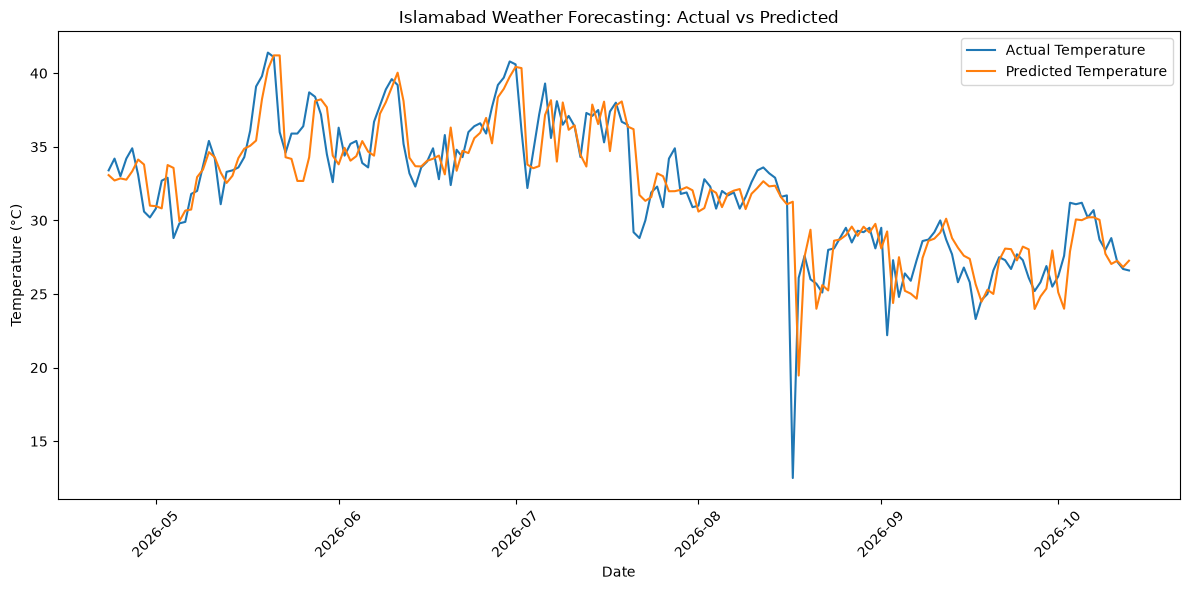

In [20]:
plt.figure(figsize=(12, 6))

plt.plot(y_test.index, y_test, label="Actual Temperature")
plt.plot(y_test.index, predictions, label="Predicted Temperature")

plt.title("Islamabad Weather Forecasting: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Future Predictions

In [21]:
future_predictions = []

history = daily_weather.tolist()

for i in range(7):
    last_day = daily_weather.index[-1] + pd.Timedelta(days=i + 1)

    lag_1 = history[-1]
    lag_7 = history[-7]
    rolling_mean_7 = np.mean(history[-7:])
    month = last_day.month

    new_data = pd.DataFrame([{
        "lag_1": lag_1,
        "lag_7": lag_7,
        "rolling_mean_7": rolling_mean_7,
        "month": month
    }])

    predicted_temp = forecast_model.predict(new_data)[0]

    future_predictions.append({
        "date": last_day,
        "predicted_temperature": round(predicted_temp, 2)
    })

    history.append(predicted_temp)

future_df = pd.DataFrame(future_predictions)

print("7-Day Islamabad Temperature Forecast")
print(future_df)

7-Day Islamabad Temperature Forecast
        date  predicted_temperature
0 2026-10-14                  26.87
1 2026-10-15                  27.62
2 2026-10-16                  27.83
3 2026-10-17                  27.66
4 2026-10-18                  27.83
5 2026-10-19                  27.87
6 2026-10-20                  27.99


Visualizing -7 Day Prediction

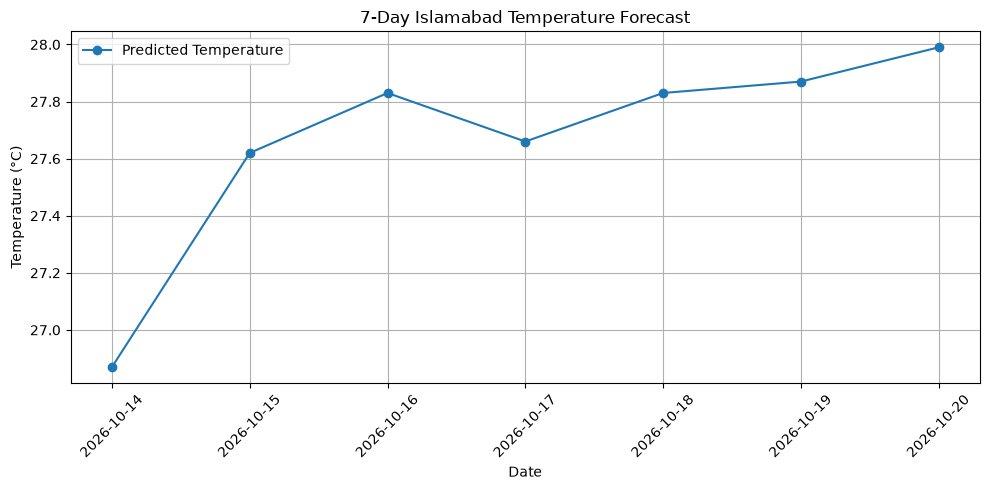

Forecast saved successfully!


In [22]:
# Visualize the 7-day predictions
plt.figure(figsize=(10, 5))

plt.plot(
    future_df["date"],
    future_df["predicted_temperature"],
    marker="o",
    label="Predicted Temperature"
)

plt.title("7-Day Islamabad Temperature Forecast")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Save forecast results
future_df.to_csv("Islamabad_7_Day_Forecast.csv", index=False)

print("Forecast saved successfully!")

## Project Conclusion

This project focused on analyzing weather patterns and developing a machine learning model to predict future temperatures in Islamabad.

The project used the Global Weather Repository dataset. Data cleaning, exploratory data analysis (EDA), geographical visualization, and anomaly detection were performed to understand weather patterns.

Three machine learning models were compared, along with an ensemble approach. A separate Random Forest forecasting model was developed using historical temperature features, including previous-day temperature, seven-day lag, rolling average, and month.

The forecasting model achieved the following test results:

- **MAE:** 1.51°C
- **RMSE:** 2.39°C
- **R² Score:** 0.716

The model was also used to generate experimental seven-day temperature predictions for Islamabad.

This project provided practical experience in data preprocessing, data visualization, time-series feature engineering, machine learning, model evaluation, and forecasting.

**Limitation:** The predictions are experimental estimates based on the available historical dataset and are not official weather forecasts.